# Joint vs R2D2M2 vs stated scales on real designs, refitted by lme4

## 1. Motivation

The [simulated datasets](simulated.ipynb) compared three ways to set the prior scales of a Bayesian generalized linear mixed model (GLMM).<br>
Only the joint prior kept the marginal R² and the links' saturation flat as the design grew.<br>
But that comparison read every measure off the ground truth, on simulated covariates.<br>
So it could not say whether a prior's levels match those of real grouped tables.

This experiment draws y on the designs of real tables instead.<br>
lme4 refits each drawn y, as it fitted the real one.<br>
If a prior could have produced the real tables, each real fit falls at a random rank among its refits.

**Contents**
1. Motivation
2. Refits
3. Measures
4. Prior structures
5. Real designs
6. Ranks
7. Outside and distance
8. Singular, saturated and failed refits
9. The slope over d
10. Finding

References

## 2. Refits

Each real table lends its design to every prior, and lme4 (Bates et al., 2015) fits both sides alike.
- **Design:** the design matrix X and each grouping factor's random-effect columns Z_k, as lme4 builds them from the table's documented formula.
- **Columns:** X's columns other than 0/1 z-scored, which the refit's intercept and slopes absorb.
- **Draws:** each a prior, its parameters and a y in the family the real table was fitted in (Gaussian, Bernoulli or Poisson).
- **Random effects:** correlated as the formula fits them, under a Lewandowski-Kurowicka-Joe (LKJ) prior for `(x | g)`, and independent for `(x || g)`.
- **Refit:** the documented formula with the drawn y as its response, so each refit is the real fit with y swapped.
- **Refits per fit and prior:** draws until 39 refits have estimates, at most 78, since the registry keeps only real fits with estimates.

### Ranks

A real fit's rank among its m refits under one prior runs from 0, below every refit, to m, above every refit.<br>
If real tables were draws from the prior, the rank would be uniform.<br>
Then 2 / (m + 1) of the fits would fall outside their refits' range, 2/40 = 5 % at m = 39.<br>
A prior meant to cover every table leaves fewer outside, as it is wider than real tables.

The ranks' histogram reads by its shape:
- **∩:** the prior is wider than real tables.
- **U:** the prior misses real tables on both sides.
- **Falling:** the refits lie above the real fits, so the prior's levels are too high.
- **Rising:** the refits lie below the real fits, so the prior's levels are too low.

## 3. Measures

Each measure is read off a fit's estimates, the refit's or the real one's, by the variance partition of [simulated.ipynb's section 3](simulated.ipynb) (Nakagawa et al., 2017).
- **$R^2_m$, $R^2_c$ and the fixed share $R^2_m / R^2_c$:** one per fit.
- **Intraclass correlation (ICC):** one per grouping factor, each paired with the same factor of the real fit.
- **sd(η):** the standard deviation of the fitted linear predictor over the rows, on the logit and log links only, since a Gaussian η is on y's raw scale.
- **Singular share:** the share of fits that lme4 flags as singular, with some variance estimated at 0 or some correlation at ±1.
- **Saturated share:** the share of fits with some |η̂| above 10, on the logit and log links only.
- **Failed share:** the share of a prior's draws whose refit ended without estimates, mostly on a y that lme4 cannot fit, constant or fixed by a saturated link.

A fit without slopes (d = 1) has $R^2_m$ = 0 and a fixed share of 0 on both sides, so it leaves those two measures.

## 4. Prior structures

The priors are [simulated.ipynb's](simulated.ipynb), with two changes.<br>
The joint prior draws at TabDGP's defaults, which [these refits set](https://github.com/adkipnis/tabdgp/issues/79), where the simulated datasets draw the earlier ones:
- **Fixed effects share:** φ ~ Beta(2, 3), not Beta(1, 1).
- **Intercept's prior scale:** LogUniform(0.1, 3), not LogUniform(0.1, 10).
- **Budget on the logit link:** τ ~ LogUniform(0.5, 3), not LogUniform(0.25, 4), which the log link keeps.

R2D2M2 runs at concentration a = 0.5 only, since the simulated datasets found that the concentration barely matters.

| prior | prior scales |
|---|---|
| `joint` | a budget τ² = var(η), split between fixed and random effects by φ |
| `r2d2m2-0.5` | R² ~ Beta(2, 2), var(η) = $\tilde\sigma^2$ R² / (1 − R²), split among all terms by a Dirichlet(0.5) |
| `survey` | one published model's stated scales per dataset |
| `unit` | a scale of 1 for every coefficient |

Every prior rescales the joint prior's draw on the same random streams.<br>
So the four share their families, their intercept and their random effects' correlations, and differ only in their scales.

## 5. Real designs

- **Registry:** real grouped tables from public sources, each with the mixed model its documentation fits, collected and fitted by lme4 in MixedBench 1.0.13.
- **Fits:** each documented model with estimates and an intercept, on the rows it was fitted on.
- **Fits left out:** the 17 slowest, whose refits took a median above 120 s and would have taken most of the cluster time.

`registry.py` builds the designs, draws and refits y, one cluster task per fit, and writes `registry.csv.gz`, which this notebook reads.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mixedbench import registry

from tabdgp import fidelity

SEED = 2026  # the ties' random draws
ESTIMATED = ['ok', 'singular', 'warning']  # the statuses of a fit with estimates
FAMILIES = ['gaussian', 'bernoulli', 'poisson']
LINKS = ['bernoulli', 'poisson']  # the families whose link saturates
BINS = 10  # the rank histograms' bins, 4 of the 40 ranks each
# each prior's arm in registry.csv.gz: the joint prior at TabDGP's defaults
# (joint-phi-tau0-logit on the logit link, whose τ differs), the rivals at its intercept
ARMS = {
    'joint': 'joint-phi-tau0',
    'r2d2m2-0.5': 'r2d2m2-0.5',
    'survey': 'survey',
    'unit': 'unit',
}
LOGIT_ARM = 'joint-phi-tau0-logit'


def selectPriors(records: pd.DataFrame) -> pd.DataFrame:
    # each prior's records under its name, on the fits the joint prior ran on
    parts = []
    for prior, arm in ARMS.items():
        selected = records['arm'] == arm
        if prior == 'joint':
            logit = records['family'] == 'bernoulli'
            selected = (selected & ~logit) | ((records['arm'] == LOGIT_ARM) & logit)
        parts.append(records[selected].assign(prior=prior))
    selected = pd.concat(parts).drop(columns='arm')
    ran = selected[selected['prior'] == 'joint']['task'].unique()
    return selected[selected['task'].isin(ran)]


fits = pd.read_csv('registry-fits.csv')  # a row per registry model, its task or why it was dropped
records = pd.read_csv('registry.csv.gz')  # a row per fit, draw and arm
tasks = fits[fits['task'].notna()].astype({'task': int, 'rank': int, 'factors': int})
records = selectPriors(records.merge(tasks[['task', 'family', 'rank']], on='task'))
tasks = tasks[tasks['task'].isin(records['task'])]
print(f'{len(tasks)} of {len(fits)} registry models, {len(records)} draws')
print(tasks['family'].value_counts()[FAMILIES].to_string())

761 of 931 registry models, 122232 draws
family
gaussian     536
bernoulli    132
poisson       93


In [2]:
MEASURES = {
    'r2_marginal': '$R^2_m$',
    'r2_conditional': '$R^2_c$',
    'fixed_share': '$R^2_m / R^2_c$',
    'icc': 'ICC',
    'sd_eta': 'sd(η)',
}
PER_FIT = ['r2_marginal', 'r2_conditional', 'fixed_share', 'sd_eta']  # one value per fit


def selectMeasures(table: pd.DataFrame) -> pd.DataFrame:
    # sd(η) only on the logit and log links, R²_m and the fixed share only on fits with slopes
    table = table.merge(tasks[['task', 'family', 'rank']], on='task')
    raw_scale = (table['family'] == 'gaussian') & (table['measure'] == 'sd_eta')
    no_slopes = (table['rank'] == 1) & table['measure'].isin(['r2_marginal', 'fixed_share'])
    return table[~raw_scale & ~no_slopes]


def readFits() -> pd.DataFrame:
    # fits.csv holds a row per grouping factor, the fit's own measures repeated on each
    reference = pd.read_csv(registry.path('fits.csv'), keep_default_na=False, na_values=[''])
    reference['id'] = (
        reference['source'] + '/' + reference['object'] + '/' + reference['model_index'].astype(str)
    )
    return reference.merge(tasks[['id', 'task']], on='id')


def readRegistry(reference: pd.DataFrame) -> pd.DataFrame:
    # the fit's own measures, the fixed share at the records' 4 decimals
    per_fit = reference.drop_duplicates('task').copy()
    explained = per_fit['sigma2_fixed'] + per_fit['sigma2_random']
    per_fit['fixed_share'] = (per_fit['sigma2_fixed'] / explained).round(4)
    measures = per_fit.melt(id_vars='task', value_vars=PER_FIT, var_name='measure')
    measures['k'] = 0

    # each factor's ICC, k in lme4's order, which is the order of a fit's rows and its refits' columns
    factors = reference[['task', 'icc']].rename(columns={'icc': 'value'})
    factors['k'] = factors.groupby('task').cumcount() + 1
    factors['measure'] = 'icc'
    return selectMeasures(pd.concat([measures, factors]).dropna(subset=['value']))


def readRefits() -> pd.DataFrame:
    # each refit's measures, a row per measure and factor
    fitted = records[records['fit_status'].isin(ESTIMATED)]
    parts = []
    for measure in PER_FIT:
        part = fitted[['task', 'draw', 'prior']].assign(
            measure=measure, k=0, value=fitted[f'fit_{measure}']
        )
        parts.append(part)
    for k in range(1, tasks['factors'].max() + 1):
        part = fitted[['task', 'draw', 'prior']].assign(
            measure='icc', k=k, value=fitted[f'fit_icc_{k}']
        )
        parts.append(part)
    return selectMeasures(pd.concat(parts).dropna(subset=['value']))


fits_table = readFits()  # fits.csv's rows of the kept fits, a row per fit and factor
real = readRegistry(fits_table)  # a row per fit, measure and factor (k = 0 for a fit's own measure)
refits = readRefits()  # a row per refit, measure and factor

## 6. Ranks

Each row of a figure is one measure.<br>
Its first panel shows the measure's distribution among the real fits and under each prior, as empirical cumulative distribution functions (CDFs).<br>
The other panels show the real fits' ranks under each prior, with the uniform share of 1/10 dashed.

In [3]:
def rankRegistry(rng: np.random.Generator) -> pd.DataFrame:
    # each real fit's estimate against the refits of its fit and factor under each prior
    paired = refits.merge(
        real[['task', 'measure', 'k', 'value']],
        on=['task', 'measure', 'k'],
        suffixes=('', '_registry'),
    )
    paired['below'] = paired['value'] < paired['value_registry']
    paired['tied'] = paired['value'] == paired['value_registry']
    ranks = paired.groupby(['family', 'measure', 'task', 'k', 'prior'], as_index=False).agg(
        below=('below', 'sum'), tied=('tied', 'sum'), refits=('value', 'size')
    )

    # the histogram's bin: ties (an ICC of 0 on a singular fit) broken at random,
    # the rank spread into BINS bins by (r + V) / (m + 1) with V uniform, for any m
    rank = ranks['below'] + rng.integers(0, ranks['tied'] + 1)
    spread = (rank + rng.random(len(ranks))) / (ranks['refits'] + 1)
    ranks['bin'] = np.floor(BINS * spread).astype(int)

    # the chance that the random tie-break puts the rank at 0 or at m
    at_bottom = (ranks['below'] == 0) / (ranks['tied'] + 1)
    at_top = (ranks['below'] + ranks['tied'] == ranks['refits']) / (ranks['tied'] + 1)
    ranks['outside'] = at_bottom + at_top
    ranks['expected'] = 2 / (ranks['refits'] + 1)  # the share outside if the ranks are uniform
    return ranks


ranks = rankRegistry(np.random.default_rng(SEED))

In [4]:
# three hues (joint, R2D2M2, stated), a dashed line for the stated priors' second
PRIOR_STYLES = {
    'joint': {'color': '#2a78d6', 'linestyle': '-'},
    'r2d2m2-0.5': {'color': '#eb6834', 'linestyle': '-'},
    'survey': {'color': '#1baf7a', 'linestyle': '-'},
    'unit': {'color': '#1baf7a', 'linestyle': '--'},
}


def plotRanks(family: str) -> None:
    # one family's distributions and ranks per measure, saved as registry-<family>.pdf
    measures = []
    for measure in MEASURES:
        if (real[real['family'] == family]['measure'] == measure).any():
            measures.append(measure)
    figure, axes = plt.subplots(
        len(measures),
        1 + len(ARMS),
        figsize=(2.125 * (1 + len(ARMS)), 2.1 * len(measures)),
        squeeze=False,
        layout='constrained',
    )
    for row, measure in enumerate(measures):
        ax = axes[row, 0]
        in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
        ax.ecdf(in_registry['value'], color='black', linewidth=2.5, label='registry')
        under_priors = refits[(refits['family'] == family) & (refits['measure'] == measure)]
        for prior in ARMS:
            under_prior = under_priors[under_priors['prior'] == prior]
            ax.ecdf(under_prior['value'], **PRIOR_STYLES[prior], label=prior)
        if measure == 'sd_eta':
            # the priors' extremes would squeeze the real fits' range of an sd
            ax.set_xscale('log')
            ax.set_xlim(in_registry['value'].min() / 10, in_registry['value'].max() * 10)
        ax.set_ylabel(MEASURES[measure])
        ax.grid(color='#e4e3df', linewidth=0.6)
        ax.spines[['top', 'right']].set_visible(False)

        # each prior's ranks, on one y scale per row
        ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
        shares = {}
        for prior in ARMS:
            bins = ranked[ranked['prior'] == prior]['bin']
            shares[prior] = np.bincount(bins, minlength=BINS) / len(bins)
        top = 1.05 * max(share.max() for share in shares.values())
        for column, prior in enumerate(ARMS, start=1):
            ax = axes[row, column]
            ax.bar(range(BINS), shares[prior], width=0.85, color=PRIOR_STYLES[prior]['color'])
            ax.axhline(1 / BINS, color='black', linestyle='--', linewidth=1)
            ax.set_ylim(0, top)
            ax.set_xticks([0, BINS - 1], ['0-3', '36-39'])
            ax.spines[['top', 'right']].set_visible(False)
            if row == 0:
                ax.set_title(prior)
            if row == len(measures) - 1:
                ax.set_xlabel("registry's rank")
    axes[0, 0].set_title('distribution')
    axes[-1, 0].set_xlabel('value')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False)
    figure.suptitle(f'{family} y')
    figure.savefig(f'registry-{family}.pdf', metadata={'CreationDate': None})

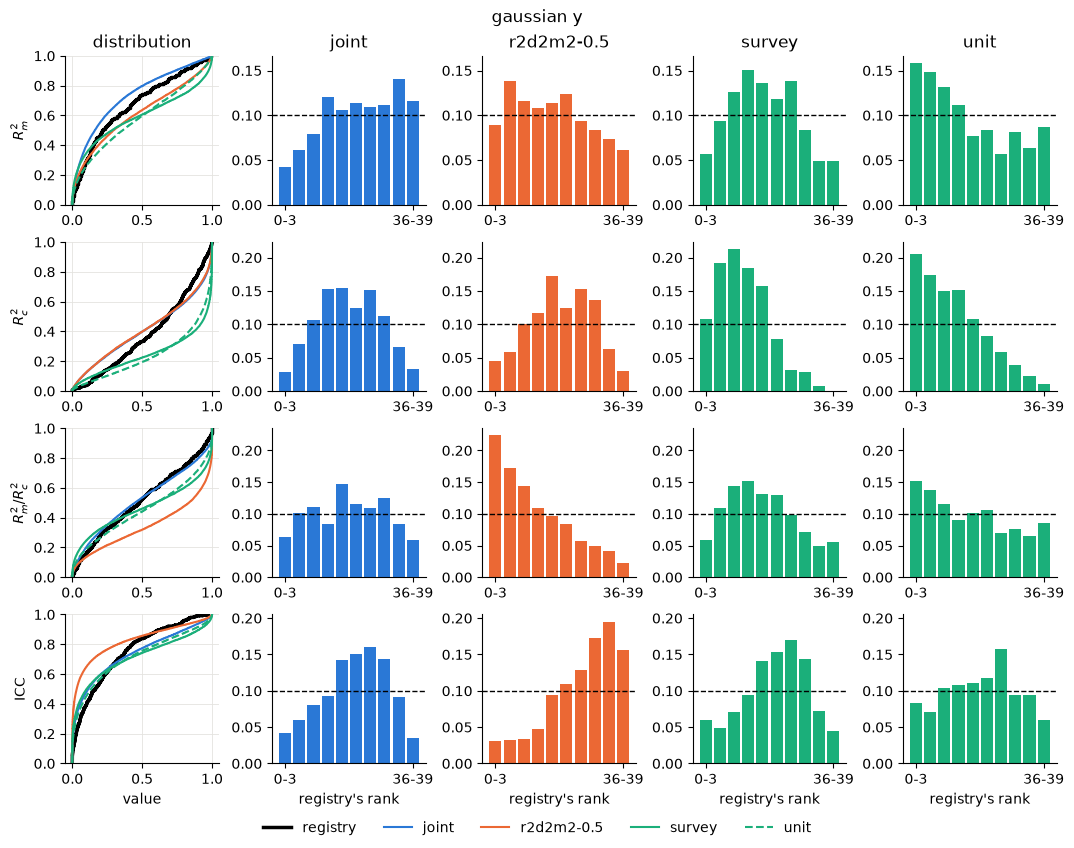

In [5]:
plotRanks('gaussian')

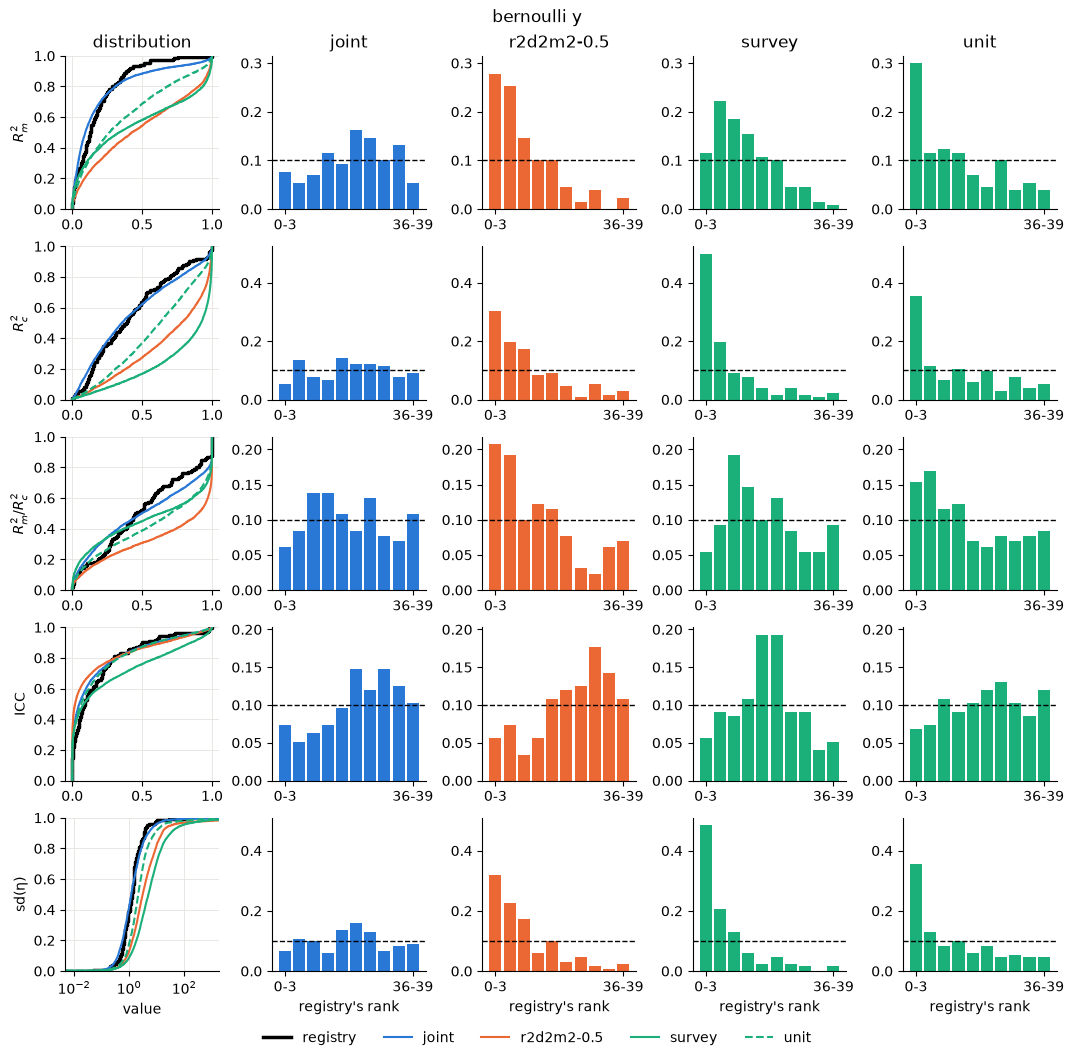

In [6]:
plotRanks('bernoulli')

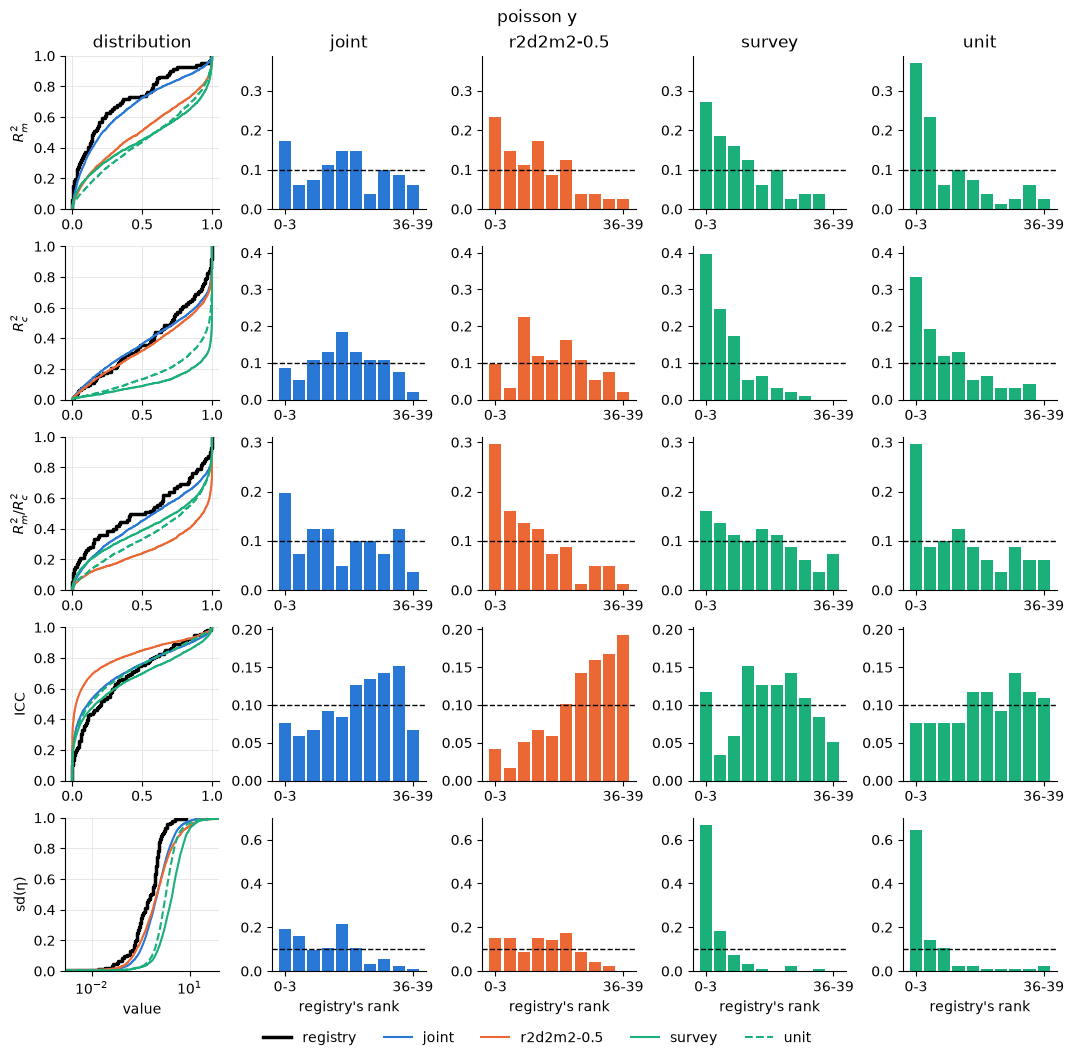

In [7]:
plotRanks('poisson')

## 7. Outside and distance

Per family, measure and prior:
- **outside:** the share of real fits outside their refits' range.
- **expected:** that share if the ranks are uniform.
- **vs joint:** the paired difference to the joint prior's share outside, with its 95 % interval by the normal approximation, clustered by fit, since a fit's factors share its design.
- **distance:** the Wasserstein-1 distance between the real fits' and the refits' measure over their pooled ranks, from 0 to 1.

In [8]:
def intervalClustered(difference: pd.Series) -> tuple[float, float]:
    # the mean's 95 % interval by the normal approximation, clustered by fit
    residuals = (difference - difference.mean()).groupby(level='task').sum()  # (fits,)
    clusters = len(residuals)
    variance = (residuals**2).sum() * clusters / (clusters - 1) / len(difference) ** 2
    half = 1.96 * math.sqrt(variance)
    return difference.mean() - half, difference.mean() + half


def comparePriors(rng: np.random.Generator) -> pd.DataFrame:
    # a row per family, measure and prior
    outside = ranks.pivot_table(
        index=['family', 'measure', 'task', 'k'], columns='prior', values='outside'
    )
    rows = []
    for family in FAMILIES:
        for measure, label in MEASURES.items():
            in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
            if in_registry.empty:
                continue
            ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
            units = outside.loc[(family, measure)]
            registry_values = in_registry['value'].to_numpy()[:, None]  # (s, 1)
            for prior in ARMS:
                under_prior = refits[
                    (refits['family'] == family)
                    & (refits['measure'] == measure)
                    & (refits['prior'] == prior)
                ]
                refit_values = under_prior['value'].to_numpy()[:, None]  # (s, 1)
                [distance] = fidelity.distances(registry_values, refit_values, rng, permutations=0)
                difference = (units[prior] - units['joint']).dropna()
                low, high = math.nan, math.nan
                if prior != 'joint':
                    low, high = intervalClustered(difference)
                rows.append(
                    {
                        'family': family,
                        'measure': label,
                        'prior': prior,
                        'outside': units[prior].mean(),
                        'expected': ranked[ranked['prior'] == prior]['expected'].mean(),
                        'vs joint': difference.mean(),
                        'low': low,
                        'high': high,
                        'distance': distance.statistic,
                    }
                )
    return pd.DataFrame(rows).set_index(['family', 'measure', 'prior'])


comparison = comparePriors(np.random.default_rng(SEED))
for family in FAMILIES:
    print(comparison.loc[family].round(3).to_string(), end='\n\n')

                            outside  expected  vs joint    low   high  distance
measure         prior                                                          
$R^2_m$         joint         0.044      0.05     0.000    NaN    NaN     0.066
                r2d2m2-0.5    0.040      0.05    -0.004 -0.021  0.013     0.056
                survey        0.028      0.05    -0.016 -0.034  0.001     0.081
                unit          0.085      0.05     0.042  0.018  0.065     0.077
$R^2_c$         joint         0.011      0.05     0.000    NaN    NaN     0.070
                r2d2m2-0.5    0.011      0.05    -0.000 -0.009  0.008     0.068
                survey        0.018      0.05     0.007 -0.004  0.018     0.195
                unit          0.050      0.05     0.038  0.020  0.056     0.181
$R^2_m / R^2_c$ joint         0.022      0.05     0.000    NaN    NaN     0.027
                r2d2m2-0.5    0.048      0.05     0.026  0.006  0.046     0.160
                survey        0.021     

## 8. Singular, saturated and failed refits

In [9]:
SHARES = ['singular', 'saturated', 'failed']

# per family, the singular and the saturated shares among the refits and the real fits,
# and the share of each prior's draws without estimates
fitted = records[records['fit_status'].isin(ESTIMATED)]
per_prior = [fitted['family'], fitted['prior']]
shares = {
    'singular': (fitted['fit_status'] == 'singular').groupby(per_prior).mean(),
    'saturated': (fitted['fit_max_abs_eta'] > 10).groupby(per_prior).mean(),
    'failed': (~records['fit_status'].isin(ESTIMATED))
    .groupby([records['family'], records['prior']])
    .mean(),
}
per_fit = fits_table.drop_duplicates('task')
in_registry = {
    'singular': (per_fit['status'] == 'singular').groupby(per_fit['family']).mean(),
    'saturated': (per_fit['max_abs_eta'] > 10).groupby(per_fit['family']).mean(),
}
table = pd.concat(shares, names=['share']).unstack('prior')[list(ARMS)]
table.insert(0, 'registry', pd.concat(in_registry, names=['share']))
table = table.swaplevel().reindex(pd.MultiIndex.from_product([FAMILIES, SHARES]))
# a Gaussian y's |η̂| is on its raw scale, so it never saturates a link
table = table.drop(index=('gaussian', 'saturated'))
print(table.round(3).to_string())

prior                registry  joint  r2d2m2-0.5  survey   unit
gaussian  singular      0.095  0.197       0.274   0.152  0.138
          failed          NaN  0.000       0.000   0.005  0.000
bernoulli singular      0.197  0.225       0.250   0.150  0.193
          saturated     0.136  0.186       0.503   0.620  0.370
          failed          NaN  0.011       0.051   0.048  0.057
poisson   singular      0.097  0.193       0.270   0.089  0.132
          saturated     0.032  0.182       0.246   0.525  0.343
          failed          NaN  0.045       0.085   0.316  0.109


## 9. The slope over d

The slope of $R^2_m$ over the design matrix's rank d says how fast the explained variance climbs with d.<br>
Each real fit's $R^2_m$, or its mean over the refits under one prior, is regressed on log₂ d.<br>
The regression is ordinary least squares (OLS) over the fits with d ≥ 2, with a 95 % interval by the normal approximation.

In [10]:
def fitSlope(d: pd.Series, r2: pd.Series) -> dict[str, float]:
    # OLS of R²_m on log₂ d, its slope's 95 % interval by the normal approximation
    centered = np.log2(d) - np.log2(d).mean()
    slope = (centered * r2).sum() / (centered**2).sum()
    residuals = r2 - r2.mean() - slope * centered
    se = math.sqrt((residuals**2).sum() / (len(r2) - 2) / (centered**2).sum())
    return {'slope': slope, 'low': slope - 1.96 * se, 'high': slope + 1.96 * se, 'fits': len(r2)}


slopes = {}
for family in FAMILIES:
    in_registry = real[(real['family'] == family) & (real['measure'] == 'r2_marginal')]
    slopes[(family, 'registry')] = fitSlope(in_registry['rank'], in_registry['value'])
    under_priors = refits[(refits['family'] == family) & (refits['measure'] == 'r2_marginal')]
    for prior in ARMS:
        under_prior = under_priors[under_priors['prior'] == prior]
        means = under_prior.groupby('task')[['rank', 'value']].mean()
        slopes[(family, prior)] = fitSlope(means['rank'], means['value'])
print(pd.DataFrame(slopes).T.round(3).to_string())

                      slope    low   high   fits
gaussian  registry    0.022  0.000  0.043  492.0
          joint       0.027  0.023  0.031  492.0
          r2d2m2-0.5  0.089  0.082  0.095  492.0
          survey      0.082  0.073  0.091  492.0
          unit        0.103  0.092  0.115  492.0
bernoulli registry    0.050  0.014  0.085  130.0
          joint       0.028  0.010  0.045  130.0
          r2d2m2-0.5  0.129  0.106  0.152  130.0
          survey      0.118  0.097  0.139  130.0
          unit        0.153  0.130  0.175  130.0
poisson   registry    0.109  0.019  0.199   81.0
          joint       0.046  0.022  0.070   81.0
          r2d2m2-0.5  0.124  0.098  0.150   81.0
          survey      0.143  0.110  0.176   81.0
          unit        0.190  0.152  0.228   81.0


## 10. Finding

### The joint prior covers real tables on the Gaussian and logit links

- **Gaussian y:** fewer real fits outside its refits' range than uniform ranks leave, on every measure.
- **Logit link:** fewer on every measure but $R^2_c$, whose 8 fits outside are each [separated or null](https://github.com/adkipnis/tabdgp/issues/79).
- **Log link:** more on $R^2_m$, the fixed share and sd(η), which every prior misses.
- **Its distance:** below 0.07 on every measure but the log link's sd(η).
- **Only it:** R2D2M2 and the survey's scales cover a Gaussian y too, but neither covers the logit link.

### R2D2M2 and the stated scales explain more than real tables on the links

- **R2D2M2:** falling ranks on the logit link's $R^2_m$, $R^2_c$ and sd(η), at five to eight times the joint prior's distance.
- **R2D2M2's split:** falling ranks on the fixed share and rising ones on the ICC on every family, as its Dirichlet hands the fixed effects the share of their terms.
- **Stated scales:** falling ranks on the links' $R^2_c$ and sd(η), with 15 % to 37 % of the fits outside.
- **The log link's sd(η):** the one measure another prior takes from the joint prior, as R2D2M2 leaves fewer fits outside at a smaller distance.
- **The slope over d:** R2D2M2's and the stated scales' $R^2_m$ climbs faster than the real fits' interval allows on a Gaussian y and on the logit link, the joint prior's within it on every link.

### Every prior misses the real fits' singular and saturated shares

- **Joint:** singular about twice as often as real fits on a Gaussian y and on the log link, and saturated more often on both links.
- **R2D2M2:** singular more often still, and saturated in half its logit refits.
- **Stated scales:** singular about as often as real fits, and the survey's saturated most often of all.
- **Failed draws:** fewest under the joint prior on both links.

### Verdict

| goal | joint prior |
|---|---|
| real fits inside its refits' range on every link | met on the Gaussian and logit links, missed on the log link, as by every prior |
| no rival with significantly fewer fits outside | met, but for R2D2M2 on the log link's sd(η) |
| $R^2_m$ climbing with d as in real tables | met |
| singular and saturated refits as often as real fits | missed |

The joint prior at TabDGP's defaults stays, as the only prior to cover both the Gaussian and the logit link.<br>
Its open gaps are the log link's measures and its singular and saturated refits.

## References

Aguilar, J. E., & Bürkner, P.-C. (2023). Intuitive joint priors for Bayesian linear multilevel models: The R2D2M2 prior. *Electronic Journal of Statistics*, *17*(1), 1711-1767. https://doi.org/10.1214/23-EJS2136

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software*, *67*(1), 1-48. https://doi.org/10.18637/jss.v067.i01

Nakagawa, S., Johnson, P. C. D., & Schielzeth, H. (2017). The coefficient of determination R² and intra-class correlation coefficient from generalized linear mixed-effects models revisited and expanded. *Journal of the Royal Society Interface*, *14*(134), 20170213. https://doi.org/10.1098/rsif.2017.0213